# Figure 1: Saturn on the simulated hard grid

Simulates the hard grid of the benchmark, fits Saturn on all 24 runs with the benchmark's settings, computes the
benchmark's own recovery and leak metrics, compares them with the published Saturn rows and axes, and draws the Saturn
panels of Fig. 1.

**Input data:** none. The data are simulated from a seed, so `inputs/fig1.json` is empty.

**Conda env:** `spatialmultivelo` (this kernel), CPU only.

**Time:** about 4 min with 24 processes of 2 threads each.

**Dropped:** GASTON, MEFISTO, MISO, SCIGMA and SpatialGlue, so the columns of panel c, the violins of panels d and e, and
all Wilcoxon brackets for those methods. The easy grid is not run: no main panel of Fig. 1 uses it.

In [1]:
import sys; sys.path.insert(0, ".")
from pathlib import Path
import pandas as pd
import nbutil as nb
nb.init("fig1")
STEPS = Path("steps").resolve()
BENCH = "results/bench_v5_full"
HARD = [f"{BENCH}/axes/hard_a{a}_c{c}_{f}_s{s}.npz" for a in (45, 90) for c in (0.8, 0.95) for f in (0.6, 0.9) for s in range(3)]

## 1. Simulate and fit
`bench_v5_full.py` runs unchanged. The wrapper `steps/fig1_saturn_bench.py` keeps only the first item of its
`all_methods()` generator, which is the Saturn fit: `train_saturn` at its defaults with the run's seed on CPU. The grid is
rotation 45 or 90 degrees, coupling 0.8 or 0.95, 60 or 90% coupled features and 3 seeds, with reverse coupling 0.2 and RNA
depth 1,000. Metrics are the benchmark's: recovery is |Spearman| with the true axis, leak is the incremental R2 of the
other true axis.

**Settings.** The transcript of the launch (2026-09-19) no longer exists. These settings come from the script and the
project notes: 24 CPU shards (`bench_full_s0..23.csv`), `SAT_THREADS` at the script default of 2, `SAT_DEVICE` at its
default of cpu. The value of `OMP_NUM_THREADS` is not recorded. A pilot of the first run was bit-identical to the published
axes with it unset and with it set to 2, so it is left unset here.

In [2]:
nb.step("saturn_hard_grid", f"python {STEPS}/fig1_saturn_bench.py --jobs 24", HARD, threads=2)

[skip] saturn_hard_grid: outputs exist


## 2. Comparison with the published Saturn results
Largest absolute difference and |r| per axis, then every numeric column of the Saturn rows. This step also checks that
`saturn.sim`, which draws panel b, and `simulate_v5`, which the benchmark uses, generate the same data.

In [3]:
nb.step("compare_published", f"python {STEPS}/fig1_compare.py", [f"{BENCH}/compare_axes.csv", f"{BENCH}/compare_table.csv"])
print(open(nb.HOLE / "logs/compare_published.log").read())

[skip] compare_published: outputs exist
axes: 24 runs x 2 axes
axis                        ATAC  RNA
truth_max_abs_diff  min      0.0  0.0
                    median   0.0  0.0
                    max      0.0  0.0
saturn_max_abs_diff min      0.0  0.0
                    median   0.0  0.0
                    max      0.0  0.0
saturn_abs_r        min      1.0  1.0
                    median   1.0  1.0
                    max      1.0  1.0
worst 5 runs/axes by |diff|:
                  run axis  truth_max_abs_diff  saturn_max_abs_diff  saturn_abs_r
hard_a90_c0.95_0.9_s0 ATAC                 0.0                  0.0           1.0
hard_a90_c0.95_0.9_s1  RNA                 0.0                  0.0           1.0
hard_a90_c0.95_0.9_s1 ATAC                 0.0                  0.0           1.0
hard_a90_c0.95_0.9_s2  RNA                 0.0                  0.0           1.0
hard_a90_c0.95_0.9_s2 ATAC                 0.0                  0.0           1.0
table, Saturn rows, 24 hard runs:
  

## 3. Summary of Saturn on the hard grid

In [4]:
T = pd.concat([pd.read_csv(f) for f in (nb.HOLE / BENCH).glob("bench_full_s*.csv")])
T = T[(T.grid == "hard") & (T.method == "Saturn")]
print(len(T), "runs")
print(T[["rec_R", "rec_A", "leak_R", "leak_A"]].agg(["mean", "median", "min", "max"]).round(4).to_string())

24 runs
         rec_R   rec_A  leak_R  leak_A
mean    0.9965  0.9997  0.0047  0.0005
median  0.9982  0.9997  0.0008  0.0002
min     0.9872  0.9992  0.0002  0.0000
max     0.9994  0.9999  0.0350  0.0028


## 4. Figure
`steps/fig1_saturn_panels.py` calls the figure's own panel functions from `fig1_model_benchmark.py`, `fig1_sim_diagram.py`
and `fig1_violin_maps.py`, unmodified, with the method list set to Saturn. Panel c shows the published representative run,
`hard_a45_c0.8_0.6_s0`. Only the page layout is new.

[run ] figure: python <repo>/reproducibility/steps/fig1_saturn_panels.py


[done] figure: 0.2 min


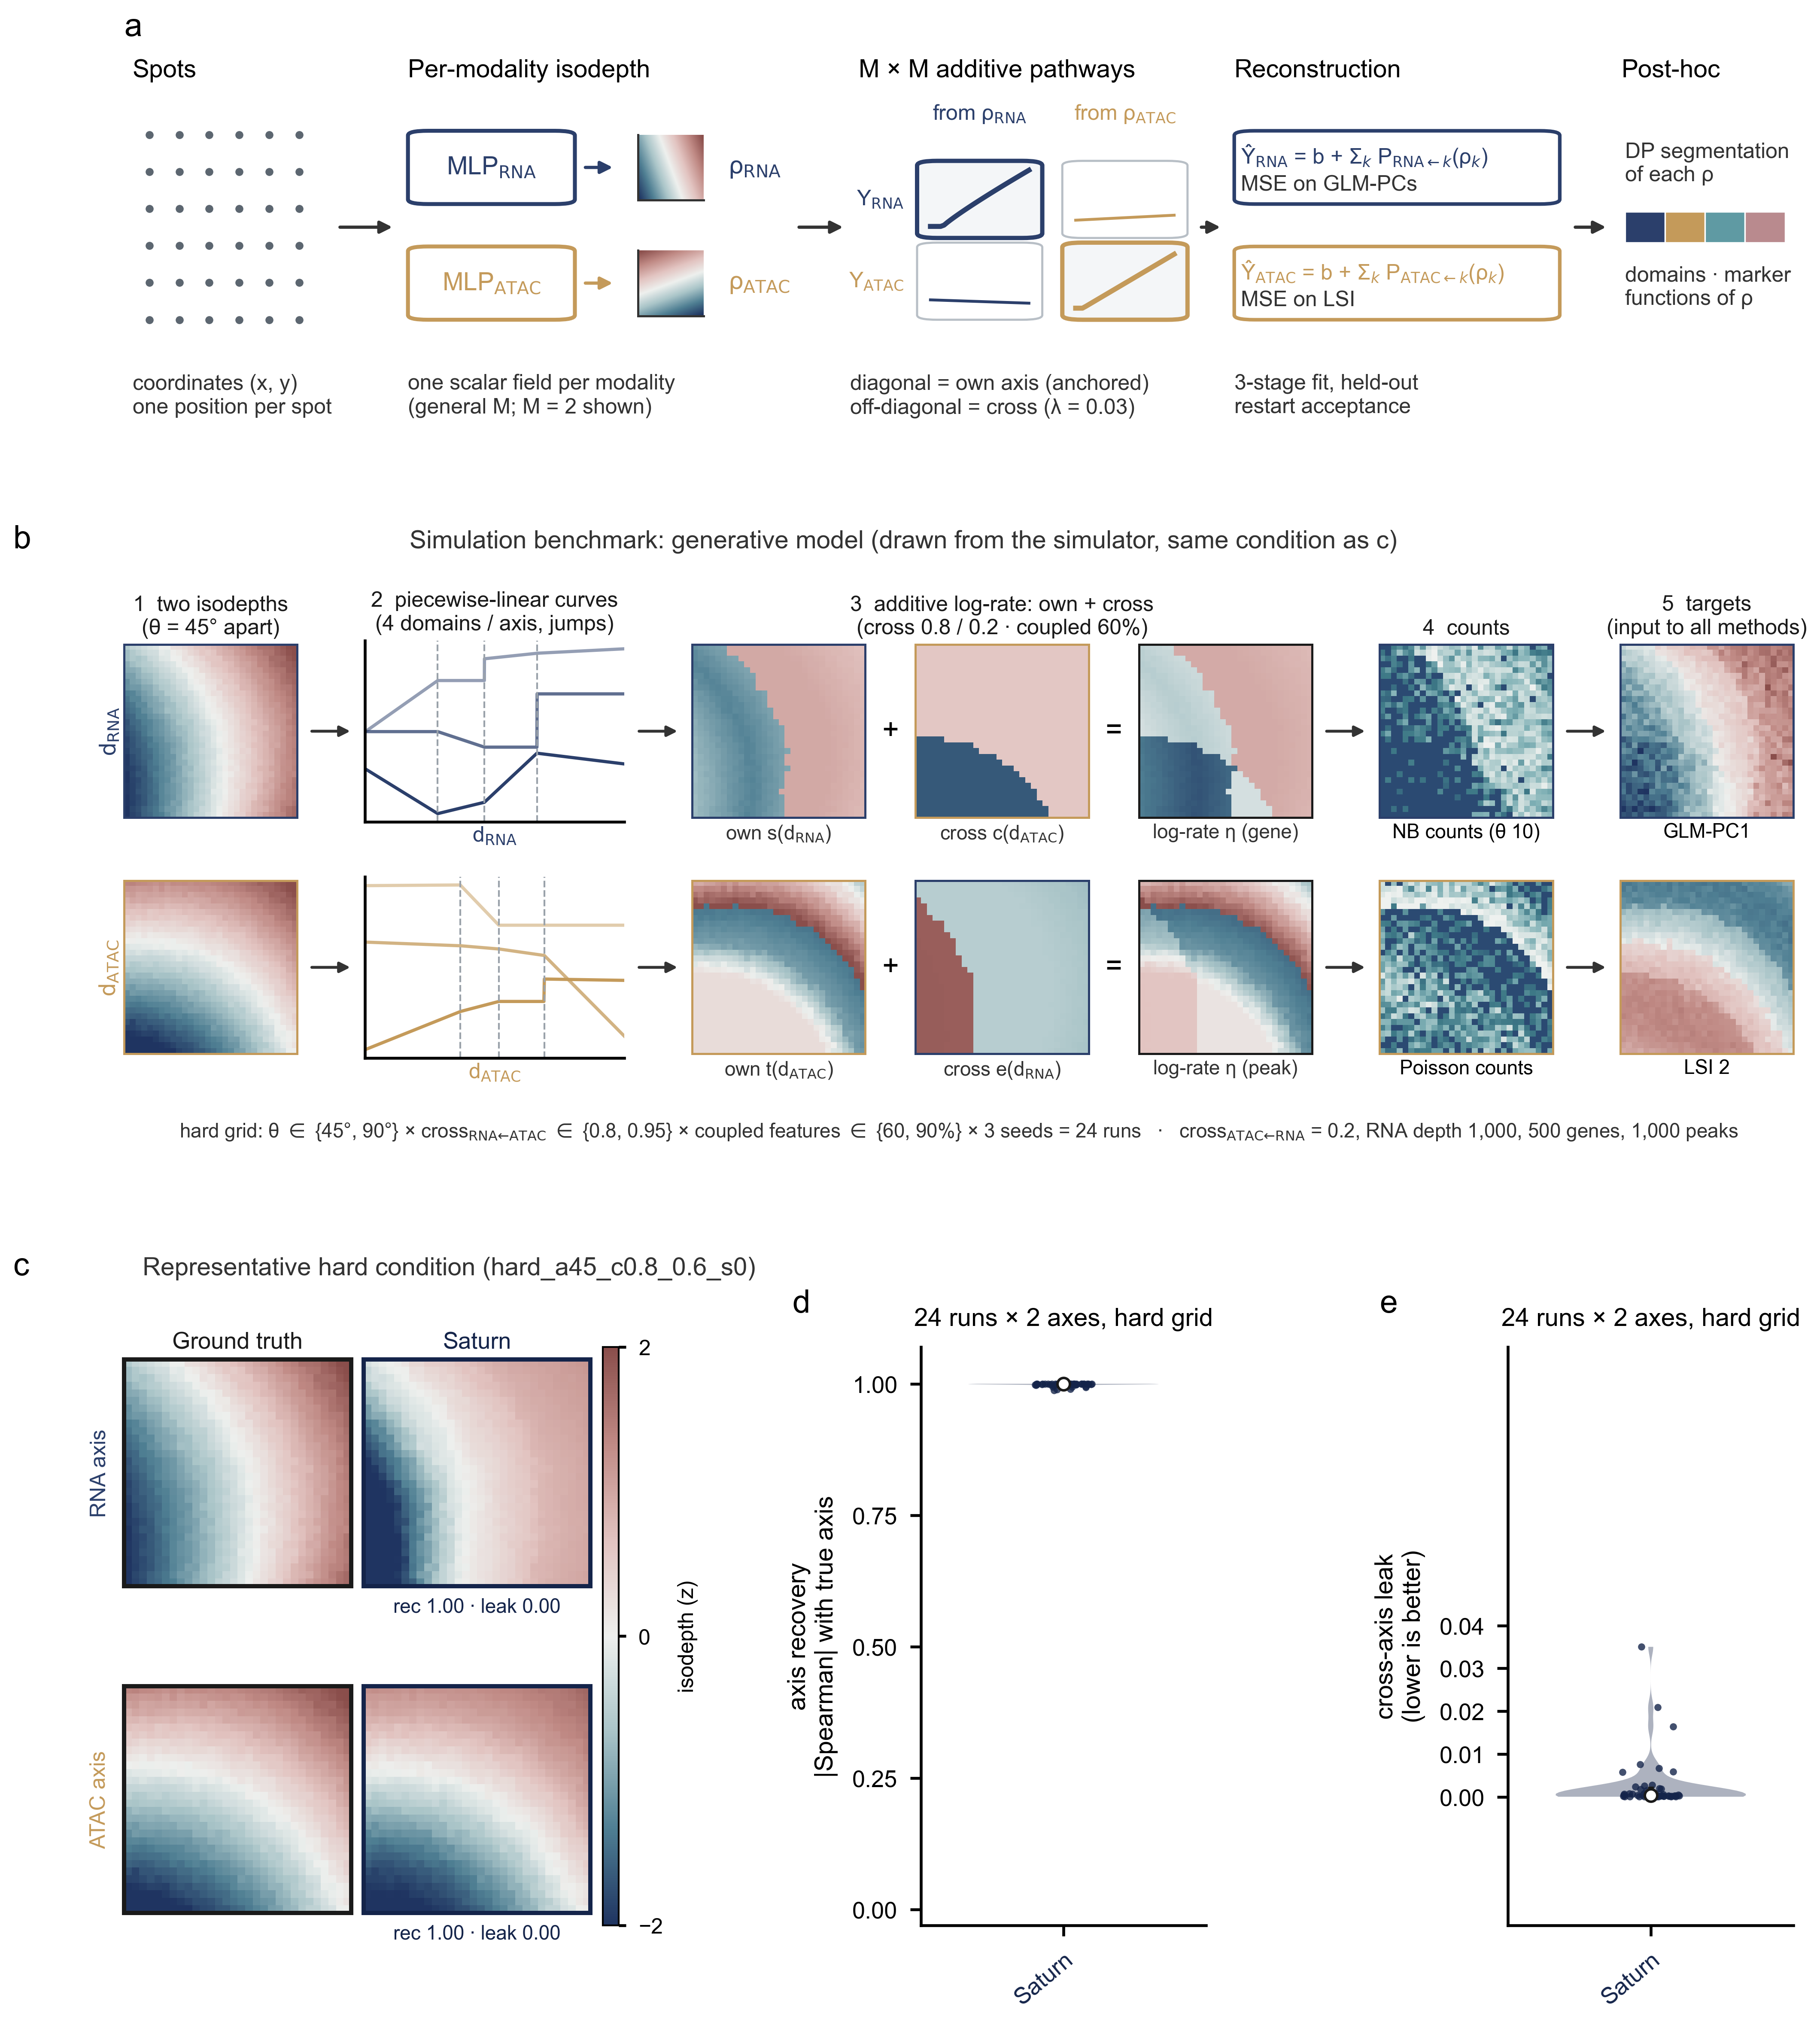

In [5]:
nb.step("figure", f"python {STEPS}/fig1_saturn_panels.py", [nb.PF / "fig1/fig1_saturn_only.png"])
nb.show("fig1/fig1_saturn_only.png", width=800)